<a href="https://colab.research.google.com/github/arnolosabas/Seminario-de-Investigacion-/blob/main/C%C3%B3digo_de_Seminario_de_Investigaci%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
import os


TOL_CERO = 1e-12
TOL_COMPARACION = 1e-10


def laplaciano(G):
    return nx.laplacian_matrix(G).toarray().astype(float)


def espectro_laplaciano(G):
    L = laplaciano(G)

    valores = np.linalg.eigvalsh(L)

    valores[np.abs(valores) < TOL_CERO] = 0.0

    return valores

In [22]:
  def entropia_desde_espectro(espectro, n):
    normalizacion = 2 * (n - 1)

    p = espectro / normalizacion
    p = p[p > TOL_CERO]

    return -np.sum(p * np.log2(p))

In [23]:
def codigo_arbol(T):
    return nx.to_graph6_bytes(
        T,
        header=False
    ).decode().strip()

In [24]:
def analizar_arbol(T, indice):
    n = T.number_of_nodes()

    espectro = espectro_laplaciano(T)
    entropia = entropia_desde_espectro(espectro, n)

    return {
        "indice": indice,
        "codigo": codigo_arbol(T),
        "entropia": entropia,
        "espectro": espectro
    }

In [25]:
def son_cospectrales(espectro1, espectro2, tol=TOL_COMPARACION):
    return np.allclose(
        espectro1,
        espectro2,
        atol=tol,
        rtol=0
    )


def son_coentropicos(S1, S2, tol=TOL_COMPARACION):
    return abs(S1 - S2) < tol

In [26]:
def buscar_candidatos(n,
                      tol_entropia=TOL_COMPARACION,
                      tol_espectro=TOL_COMPARACION):

    datos = []

    for indice, T in enumerate(nx.nonisomorphic_trees(n)):
        datos.append(
            analizar_arbol(T, indice)
        )

    datos.sort(
        key=lambda x: x["entropia"]
    )

    candidatos = []

    for i in range(len(datos)):

        for j in range(i + 1, len(datos)):

            diferencia = (
                datos[j]["entropia"]
                - datos[i]["entropia"]
            )

            if diferencia >= tol_entropia:
                break

            if not son_cospectrales(
                datos[i]["espectro"],
                datos[j]["espectro"],
                tol_espectro
            ):

                candidatos.append({
                    "indice1": datos[i]["indice"],
                    "indice2": datos[j]["indice"],

                    "codigo1": datos[i]["codigo"],
                    "codigo2": datos[j]["codigo"],

                    "entropia1": datos[i]["entropia"],
                    "entropia2": datos[j]["entropia"],

                    "diferencia": diferencia,

                    "espectro1": datos[i]["espectro"],
                    "espectro2": datos[j]["espectro"]
                })

    return candidatos

In [27]:
def arbol_desde_codigo(codigo):
    return nx.from_graph6_bytes(
        codigo.encode()
    )

In [28]:
def propiedades_estructurales(codigo):
    T = arbol_desde_codigo(codigo)

    grados = [
        d for v, d in T.degree()
    ]

    grados.sort(reverse=True)

    return {
        "grados": grados,
        "grado_maximo": max(grados),
        "hojas": sum(d == 1 for d in grados),
        "diametro": nx.diameter(T),
        "radio": nx.radius(T),
        "zagreb1": sum(d**2 for d in grados)
    }

In [29]:
def layout_arbol_jerarquico(T, raiz=None, ancho=2.0, nivel_y=1.8):
    if raiz is None:
        raiz = nx.center(T)[0]

    parent = {raiz: None}
    niveles = {}
    niveles[0] = [raiz]

    cola = deque([(raiz, 0)])

    while cola:
        u, nivel = cola.popleft()

        hijos = []
        for v in sorted(T.neighbors(u)):
            if v != parent[u]:
                parent[v] = u
                hijos.append(v)

        if hijos:
            if nivel + 1 not in niveles:
                niveles[nivel + 1] = []
            niveles[nivel + 1].extend(hijos)

            for h in hijos:
                cola.append((h, nivel + 1))

    pos = {}

    for nivel, nodos in niveles.items():
        m = len(nodos)

        if m == 1:
            xs = [0.0]
        else:
            xs = np.linspace(-(m - 1) / 2, (m - 1) / 2, m) * ancho

        y = -nivel * nivel_y

        for x, nodo in zip(xs, nodos):
            pos[nodo] = (x, y)

    return pos

In [30]:
def dibujar_arbol_bonito(T, ax, titulo=""):
    centro = nx.center(T)
    hojas = [v for v, d in T.degree() if d == 1]
    internos = [v for v in T.nodes() if v not in hojas and v not in centro]

    raiz = centro[0]
    pos = layout_arbol_jerarquico(T, raiz=raiz)

    nx.draw_networkx_edges(
        T, pos, ax=ax,
        width=2.0,
        edge_color="gray"
    )

    if internos:
        nx.draw_networkx_nodes(
            T, pos, ax=ax,
            nodelist=internos,
            node_size=700,
            node_color="#8ecae6",
            edgecolors="black",
            linewidths=1.2
        )

    if hojas:
        nx.draw_networkx_nodes(
            T, pos, ax=ax,
            nodelist=hojas,
            node_size=700,
            node_color="#b7e4c7",
            edgecolors="black",
            linewidths=1.2
        )

    if centro:
        nx.draw_networkx_nodes(
            T, pos, ax=ax,
            nodelist=centro,
            node_size=760,
            node_color="#ffb703",
            edgecolors="black",
            linewidths=1.5
        )

    nx.draw_networkx_labels(
        T, pos, ax=ax,
        font_size=11,
        font_weight="bold"
    )

    ax.set_title(titulo, fontsize=12)
    ax.axis("off")

In [31]:
def dibujar_candidato(c, guardar=False, carpeta="imagenes_candidatos"):
    T1 = arbol_desde_codigo(c["codigo1"])
    T2 = arbol_desde_codigo(c["codigo2"])

    prop1 = propiedades_estructurales(c["codigo1"])
    prop2 = propiedades_estructurales(c["codigo2"])

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    titulo1 = (
        f'T1 (índice {c["indice1"]})\n'
        f'S = {c["entropia1"]:.12f}\n'
        f'grados = {prop1["grados"]}\n'
        f'hojas = {prop1["hojas"]}, diámetro = {prop1["diametro"]}'
    )

    titulo2 = (
        f'T2 (índice {c["indice2"]})\n'
        f'S = {c["entropia2"]:.12f}\n'
        f'grados = {prop2["grados"]}\n'
        f'hojas = {prop2["hojas"]}, diámetro = {prop2["diametro"]}'
    )

    dibujar_arbol_bonito(T1, axes[0], titulo1)
    dibujar_arbol_bonito(T2, axes[1], titulo2)

    fig.suptitle(
        f'Candidato coentrópico no cospectral\n'
        f'diferencia de entropía = {c["diferencia"]:.3e}',
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout(rect=[0, 0, 1, 0.92])

    if guardar:
        os.makedirs(carpeta, exist_ok=True)
        nombre = f'{carpeta}/candidato_{c["indice1"]}_{c["indice2"]}.png'
        plt.savefig(nombre, dpi=300, bbox_inches="tight")

    plt.show()

In [32]:
def dibujar_todos_los_candidatos(candidatos, guardar=False, carpeta="imagenes_candidatos"):
    for k, c in enumerate(candidatos, start=1):
        print(f"Candidato {k}: árboles {c['indice1']} y {c['indice2']}")
        dibujar_candidato(c, guardar=guardar, carpeta=carpeta)

In [ ]:
num=17
candidatos = buscar_candidatos(num)
print("Número de candidatos:", len(candidatos))

In [34]:
for k, c in enumerate(candidatos, start=1):
    datos_T1 = propiedades_estructurales(c["codigo1"])
    datos_T2 = propiedades_estructurales(c["codigo2"])

    print("Candidato", k)
    print("Árboles:", c["indice1"], c["indice2"])
    print("T1:", datos_T1)
    print("T2:", datos_T2)
    print()

Candidato 1
Árboles: 27696 45384
T1: {'grados': [4, 3, 3, 3, 3, 3, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'grado_maximo': 4, 'hojas': 9, 'diametro': 7, 'radio': 4, 'zagreb1': 78}
T2: {'grados': [4, 4, 3, 3, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1], 'grado_maximo': 4, 'hojas': 8, 'diametro': 6, 'radio': 3, 'zagreb1': 78}

Candidato 2
Árboles: 14051 15910
T1: {'grados': [4, 3, 3, 3, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1], 'grado_maximo': 4, 'hojas': 7, 'diametro': 9, 'radio': 5, 'zagreb1': 74}
T2: {'grados': [4, 3, 3, 3, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1], 'grado_maximo': 4, 'hojas': 7, 'diametro': 9, 'radio': 5, 'zagreb1': 74}



Candidato 1: árboles 27696 y 45384


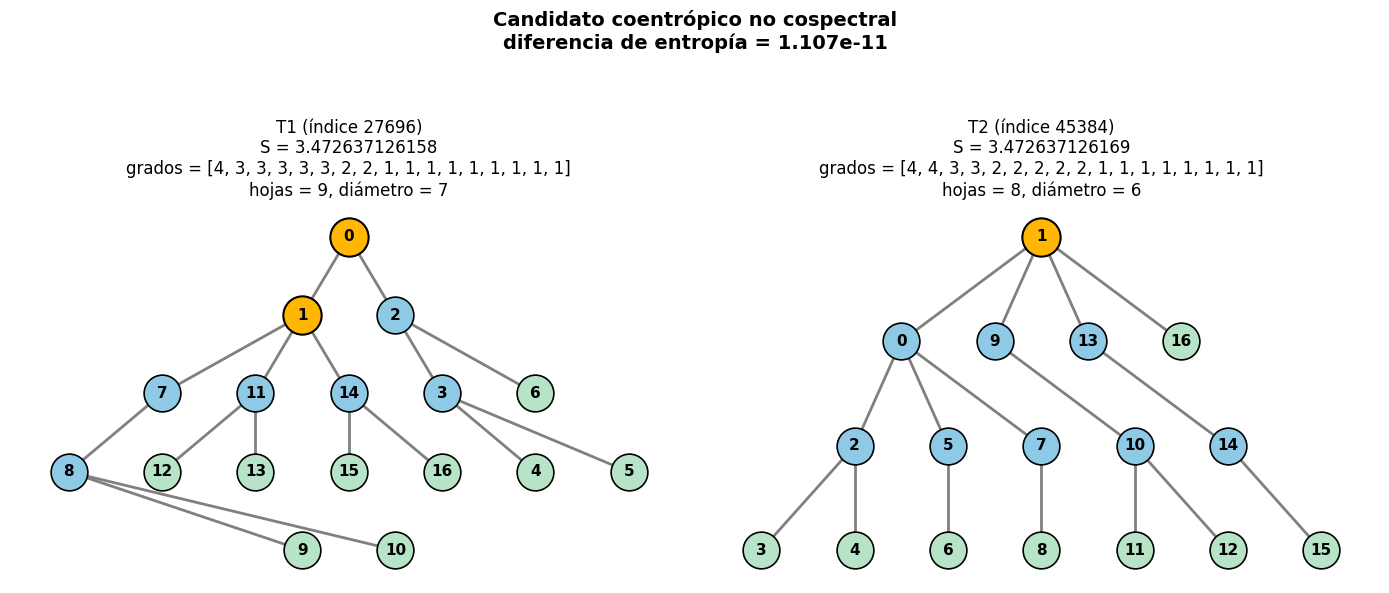

Candidato 2: árboles 14051 y 15910


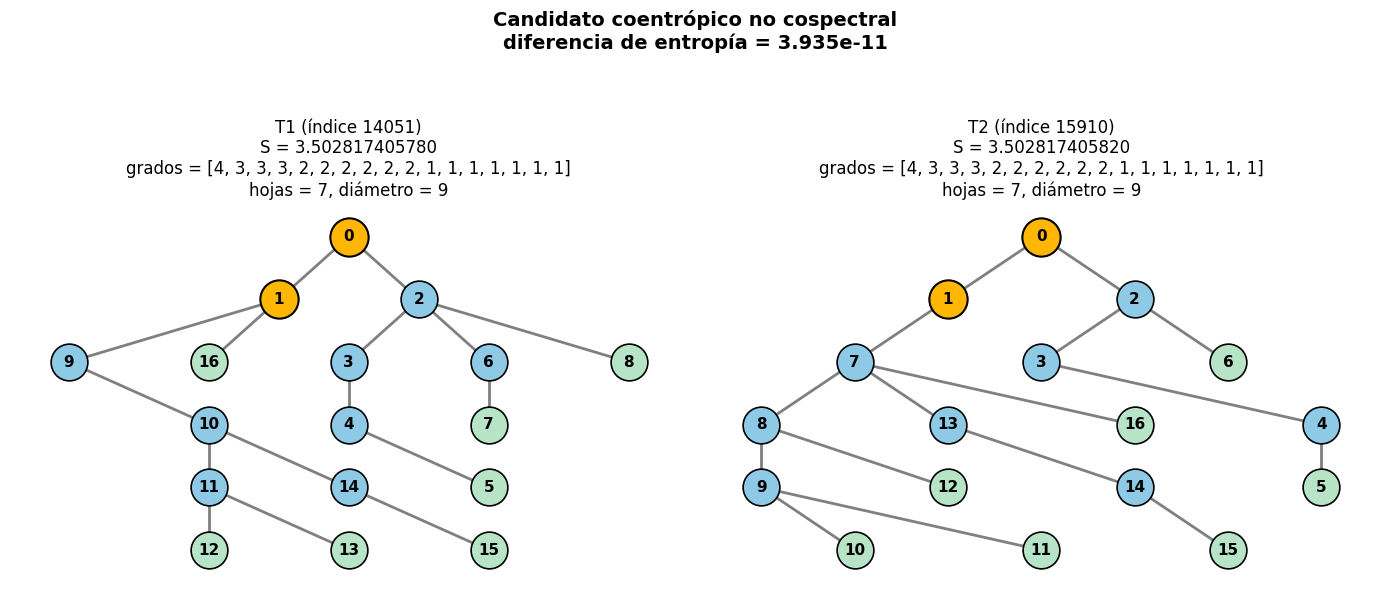

In [35]:
dibujar_todos_los_candidatos(candidatos)

Candidato 1: árboles 1 y 0


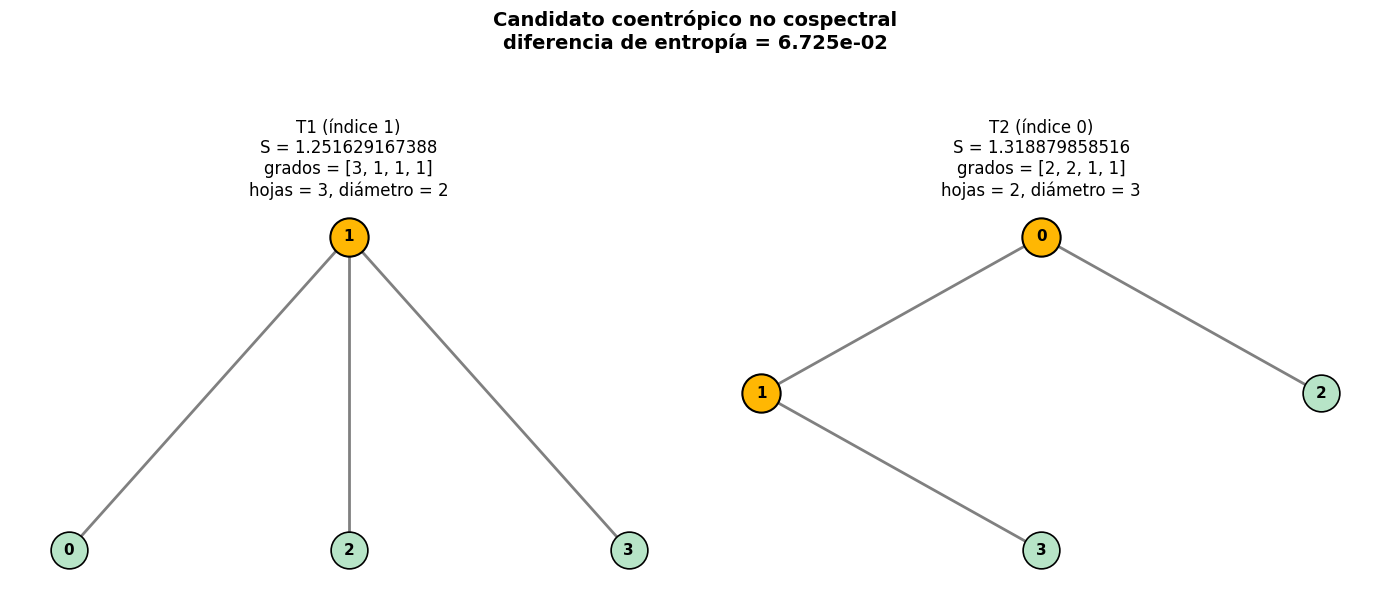

In [36]:
def buscar_candidatos(n,
                      tol_entropia=TOL_COMPARACION,
                      tol_espectro=TOL_COMPARACION):

    datos = []

    for indice, T in enumerate(nx.nonisomorphic_trees(n)):
        datos.append(
            analizar_arbol(T, indice)
        )

    datos.sort(
        key=lambda x: x["entropia"]
    )

    candidatos = []

    for i in range(len(datos)):

        for j in range(i + 1, len(datos)):

            diferencia = (
                datos[j]["entropia"]
                - datos[i]["entropia"]
            )


            candidatos.append({
                "indice1": datos[i]["indice"],
                "indice2": datos[j]["indice"],

                "codigo1": datos[i]["codigo"],
                "codigo2": datos[j]["codigo"],

                "entropia1": datos[i]["entropia"],
                "entropia2": datos[j]["entropia"],

                "diferencia": diferencia,

                "espectro1": datos[i]["espectro"],
                "espectro2": datos[j]["espectro"]
            })

    return candidatos

candidatos=buscar_candidatos(4)
dibujar_todos_los_candidatos(candidatos,guardar=True)